# M03: Nghiên cứu Bóc tách Tiền xử lý (Preprocessing Ablation Analysis P0 → P3)

**Mục tiêu nghiên cứu:** Trả lời toàn diện **Câu hỏi Nghiên cứu RQ2** (theo Mục 10.3 và Phần B4/D3 của `docs/project_handbook.md`):  
> *"Tiền xử lý ảnh hưởng như thế nào đến chất lượng phân cụm tiếng Việt? Các kỹ thuật chuẩn hóa, tách từ ghép và lọc từ dừng đóng góp cụ thể ra sao vào độ thuần khiết của cụm và khả năng diễn giải ngữ nghĩa của con người?"*  

Đồng thời giải thích hiện tượng theo yêu cầu của giảng viên hướng dẫn:  
> *"Trường hợp điểm số tự động cao nhưng topic khó diễn giải: Phân tích nguyên nhân (ví dụ: từ dừng, đa nghĩa, kích thước cụm không đều, phân bố từ vựng bị lệch). Minh họa bằng ví dụ cụ thể từ kết quả mô hình. So sánh với các chủ đề có điểm số tốt và dễ diễn giải."*

## 1. Thiết lập Môi trường & Nạp Dữ liệu Thực nghiệm
Nguyên tắc kiểm soát biến chặt chẽ (*Ceteris Paribus*):
- Cùng tập bài báo: Train 6,493 bài, Validation 1,391 bài (từ `data/splits/split_manifest.csv`).
- Cùng thuật toán K-Means: $K=9$ (mô hình chọn tối ưu từ Task M02), khởi tạo `k-means++`, 5 random seeds [42, 43, 44, 45, 46].
- Cùng tham số TF-IDF: max_features=20,000, sublinear_tf=True, norm='l2', min_df=2, max_df=0.85.
- Cơ chế bảo vệ cô lập (*Technical Isolation Guard*): `lowercase=False`, `stopwords_file=None` trong TfidfVectorizer để bảo toàn nguyên trạng đặc trưng từng biến thể P0 → P3.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Cấu hình đường dẫn thư mục gốc
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "vietnamese-news-topic-discovery" else Path(".").resolve()
RESULTS_DIR = PROJECT_ROOT / "results" / "kmeans"
FIGURES_DIR = RESULTS_DIR / "figures"

print(f"Thư mục kết quả: {RESULTS_DIR}")
print(f"Thư mục biểu đồ:  {FIGURES_DIR}")

Thư mục kết quả: D:\HK5\NLP\NLP_Project\vietnamese-news-topic-discovery\results\kmeans
Thư mục biểu đồ:  D:\HK5\NLP\NLP_Project\vietnamese-news-topic-discovery\results\kmeans\figures


## 2. Bảng Tổng hợp Kết quả Đo lường Định lượng ($K=9$)
Đo lường trên tập Validation (1,391 bài báo), hoàn toàn độc lập và tuân thủ nguyên tắc **Zero Label Leakage**.

In [2]:
metrics_path = RESULTS_DIR / "m03_preprocessing_ablation_metrics.csv"
metrics_df = pd.read_csv(metrics_path)

# Hiển thị các cột cốt lõi
display_cols = [
    "variant_id",
    "variant_name",
    "vocab_size",
    "val_sparsity_pct",
    "val_oov_rate_pct",
    "val_mean_active_terms",
    "silhouette_score",
    "davies_bouldin_index",
    "calinski_harabasz_score",
    "purity",
    "nmi",
    "ari",
    "stability_ari_mean",
    "compound_keyword_ratio_pct",
    "stopword_keyword_ratio_pct",
    "topic_diversity_top10",
]

styled = metrics_df[display_cols].style.format({
    "val_sparsity_pct": "{:.2f}%".format,
    "val_oov_rate_pct": "{:.2f}%".format,
    "val_mean_active_terms": "{:.1f}".format,
    "silhouette_score": "{:.4f}".format,
    "davies_bouldin_index": "{:.4f}".format,
    "calinski_harabasz_score": "{:.2f}".format,
    "purity": "{:.2%}".format,
    "nmi": "{:.4f}".format,
    "ari": "{:.4f}".format,
    "stability_ari_mean": "{:.4f}".format,
    "compound_keyword_ratio_pct": "{:.1f}%".format,
    "stopword_keyword_ratio_pct": "{:.1f}%".format,
    "topic_diversity_top10": "{:.4f}".format,
}).highlight_max(
    subset=["purity", "nmi", "ari", "stability_ari_mean", "compound_keyword_ratio_pct", "topic_diversity_top10"],
    color="#d1e7dd"
).highlight_min(
    subset=["davies_bouldin_index", "val_oov_rate_pct", "stopword_keyword_ratio_pct"],
    color="#d1e7dd"
)

styled

,variant_id,variant_name,vocab_size,val_sparsity_pct,val_oov_rate_pct,val_mean_active_terms,silhouette_score,davies_bouldin_index,calinski_harabasz_score,purity,nmi,ari,stability_ari_mean,compound_keyword_ratio_pct,stopword_keyword_ratio_pct,topic_diversity_top10
0,P0,P0_minimal,17983,98.34%,9.86%,299.3,0.0193,5.7112,13.15,83.61%,0.6652,0.5457,0.8599,0.0%,9.6%,0.9000
1,P1,P1_normalized,15285,98.17%,11.04%,279.9,0.0186,5.5708,14.17,81.52%,0.6503,0.5161,0.8267,0.0%,9.6%,0.8778
2,P2,P2_segmented,20000,98.79%,11.97%,241.8,0.0181,6.1151,11.50,81.60%,0.6494,0.4958,0.8186,32.6%,18.5%,0.9222
3,P3,P3_no_stopwords,20000,99.05%,2.56%,190.8,0.0190,6.1566,11.38,87.28%,0.7004,0.5925,0.8211,43.7%,0.0%,0.9556


## 3. Trực quan hóa Nghiên cứu & Nghịch lý Chỉ số Nội tại

### 3.1. So sánh Chỉ số Ngoại vi & Độ ổn định Đa seed
Biến thể **P3 (Lọc từ dừng)** tạo bước nhảy vọt toàn diện về độ thuần khiết và độ chính xác phân cụm.

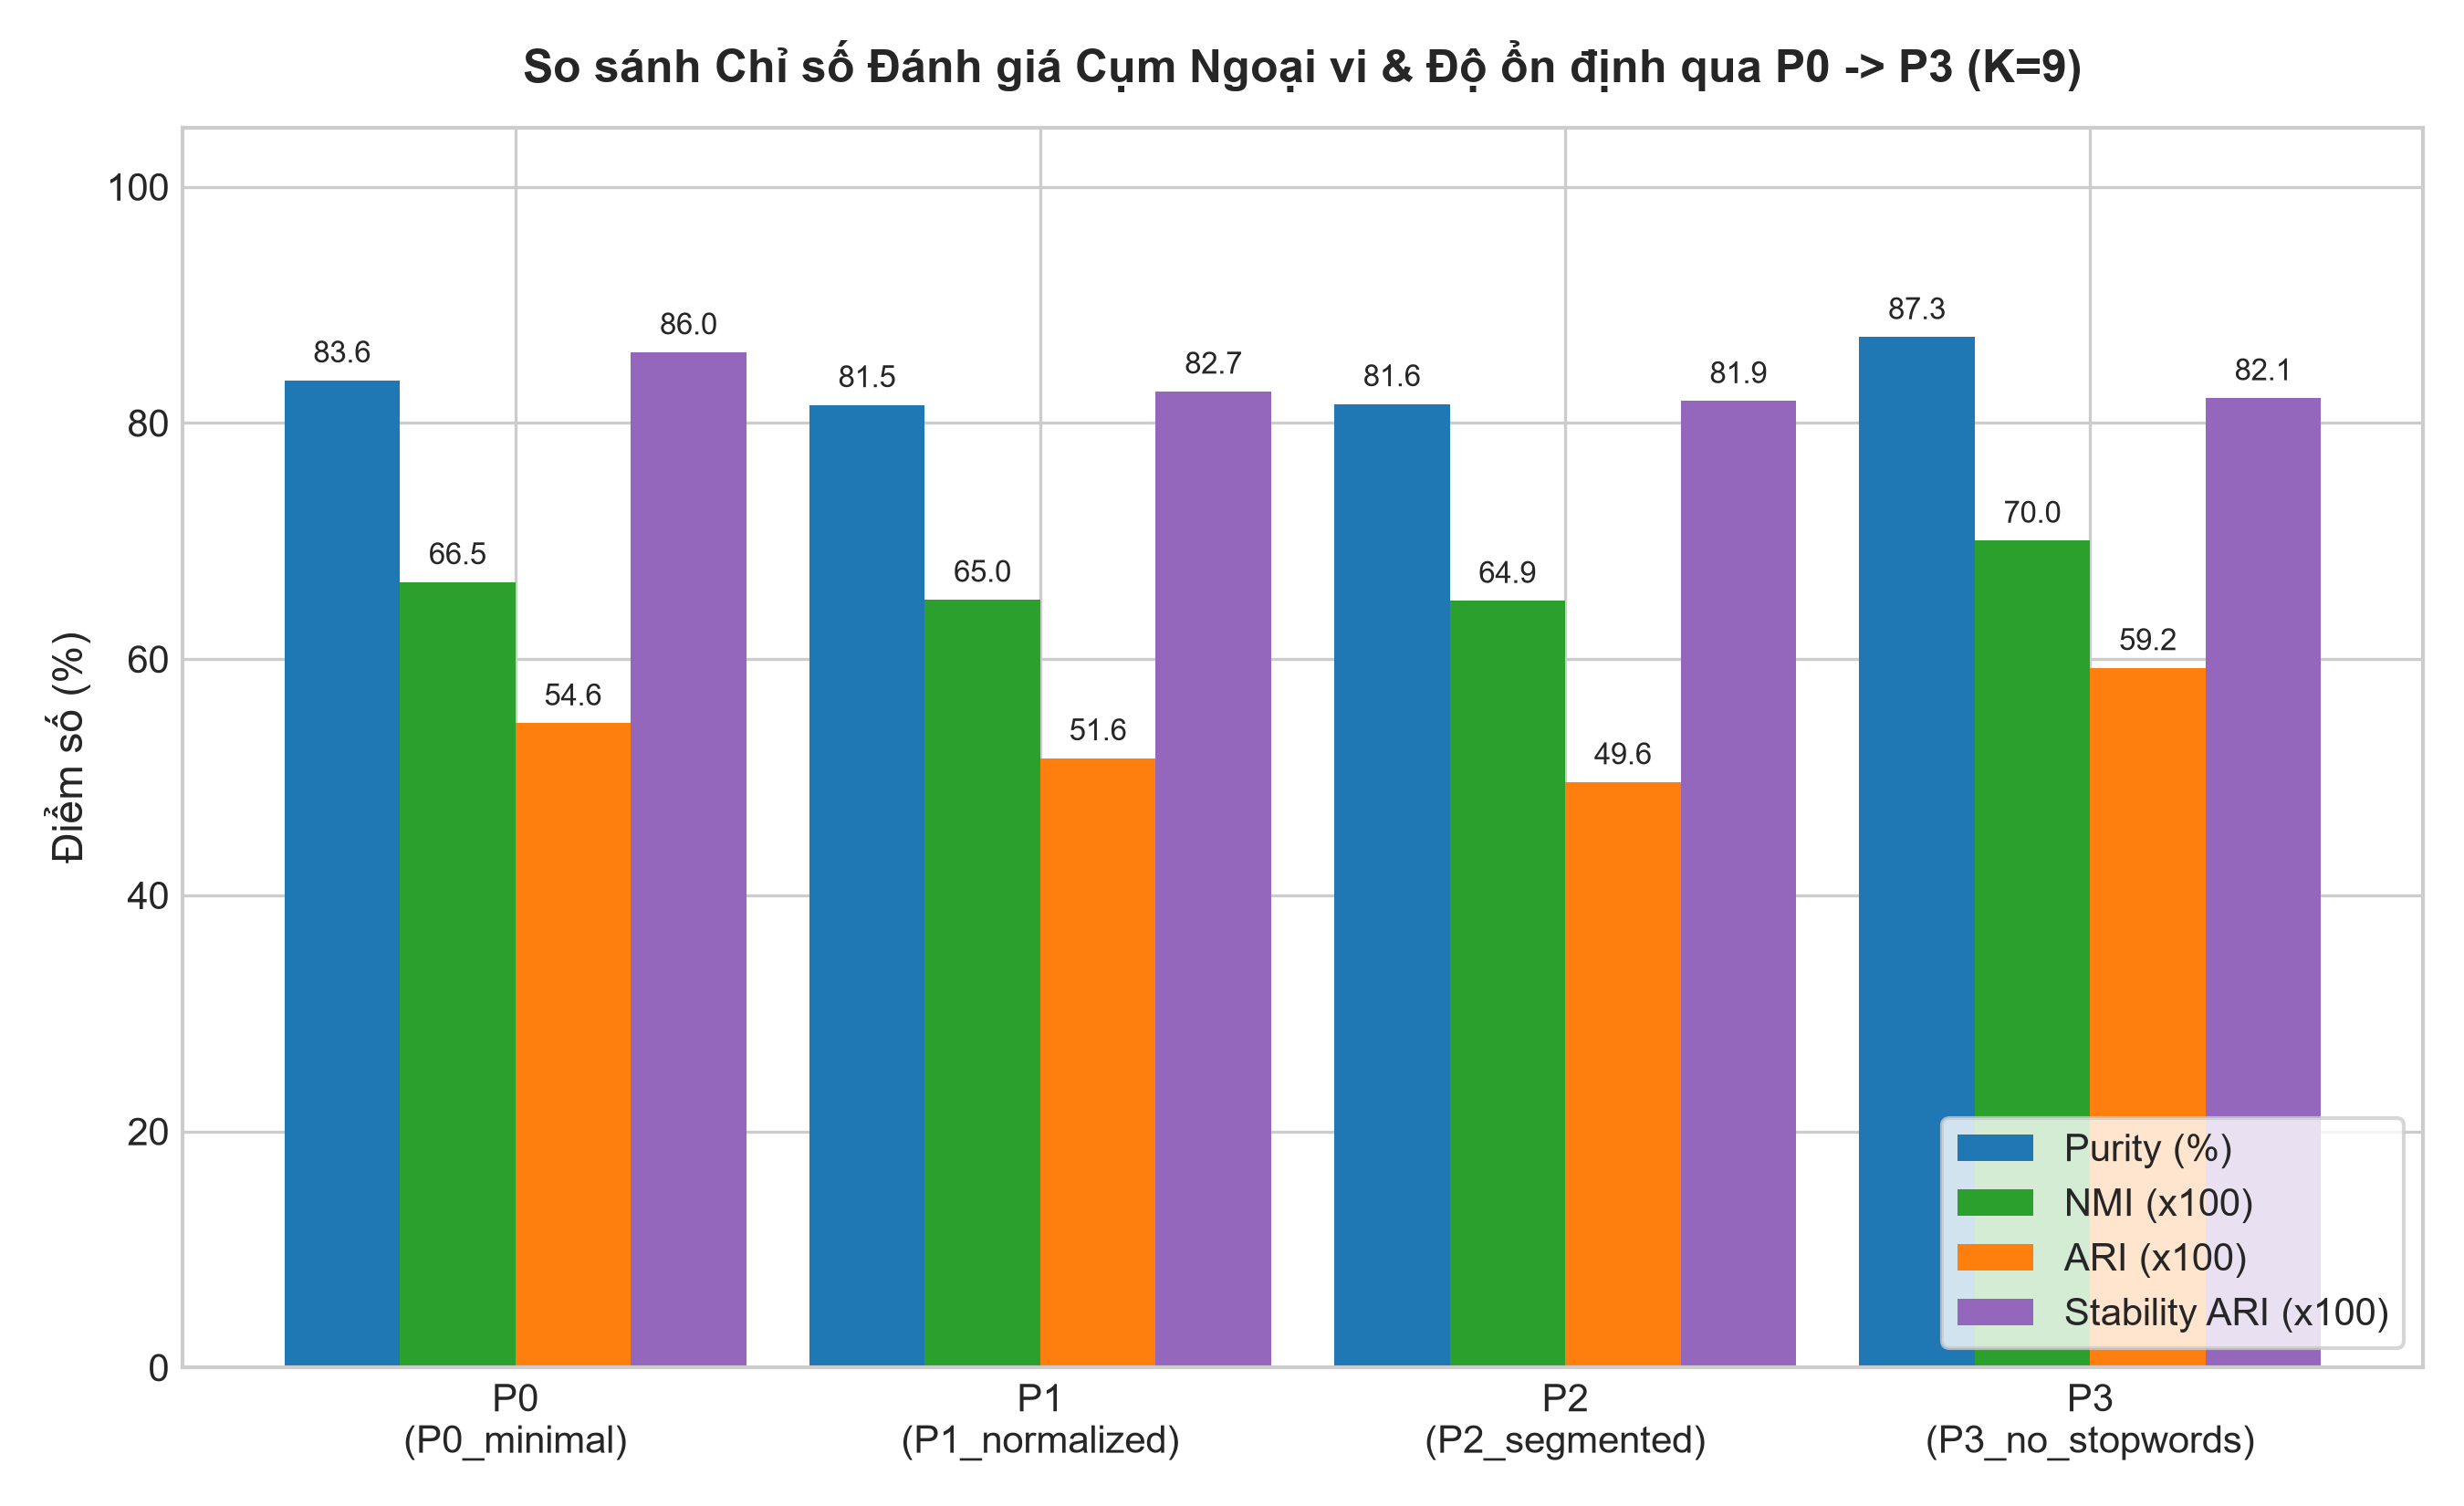

In [3]:
display(Image(filename=str(FIGURES_DIR / "m03_ablation_metrics_comparison.png")))

### 3.2. Nghịch lý Chỉ số Nội tại (Intrinsic vs Extrinsic Paradox)
**Giải thích câu hỏi của Giảng viên hướng dẫn:**
- P1 đạt Davies-Bouldin tốt nhất (5.5708) và Calinski-Harabasz cao nhất (14.17), nhưng Purity và NMI lại thấp nhất (81.52% và 0.6503).
- **Nguyên nhân toán học:** Ở P0 và P1, các âm tiết đơn lẻ tần suất cao (`các`, `của`, `người`, `và`) đóng vai trò "trọng lực giả", kéo các vector tài liệu lại gần nhau trong không gian Euclid đa chiều, tạo ảo giác co cụm chặt.
- **Nguyên nhân ngữ nghĩa:** Các cụm hình thành bị vỡ vụn nghĩa (âm tiết đơn què cụt) và ngập tràn từ dừng. Khi loại bỏ từ dừng ở P3, vector tỏa rộng theo ngữ nghĩa thực tế: DBI tăng nhẹ lên 6.1566 nhưng Purity tăng vọt lên **87.28%** và ARI tăng vọt lên **0.5925**.

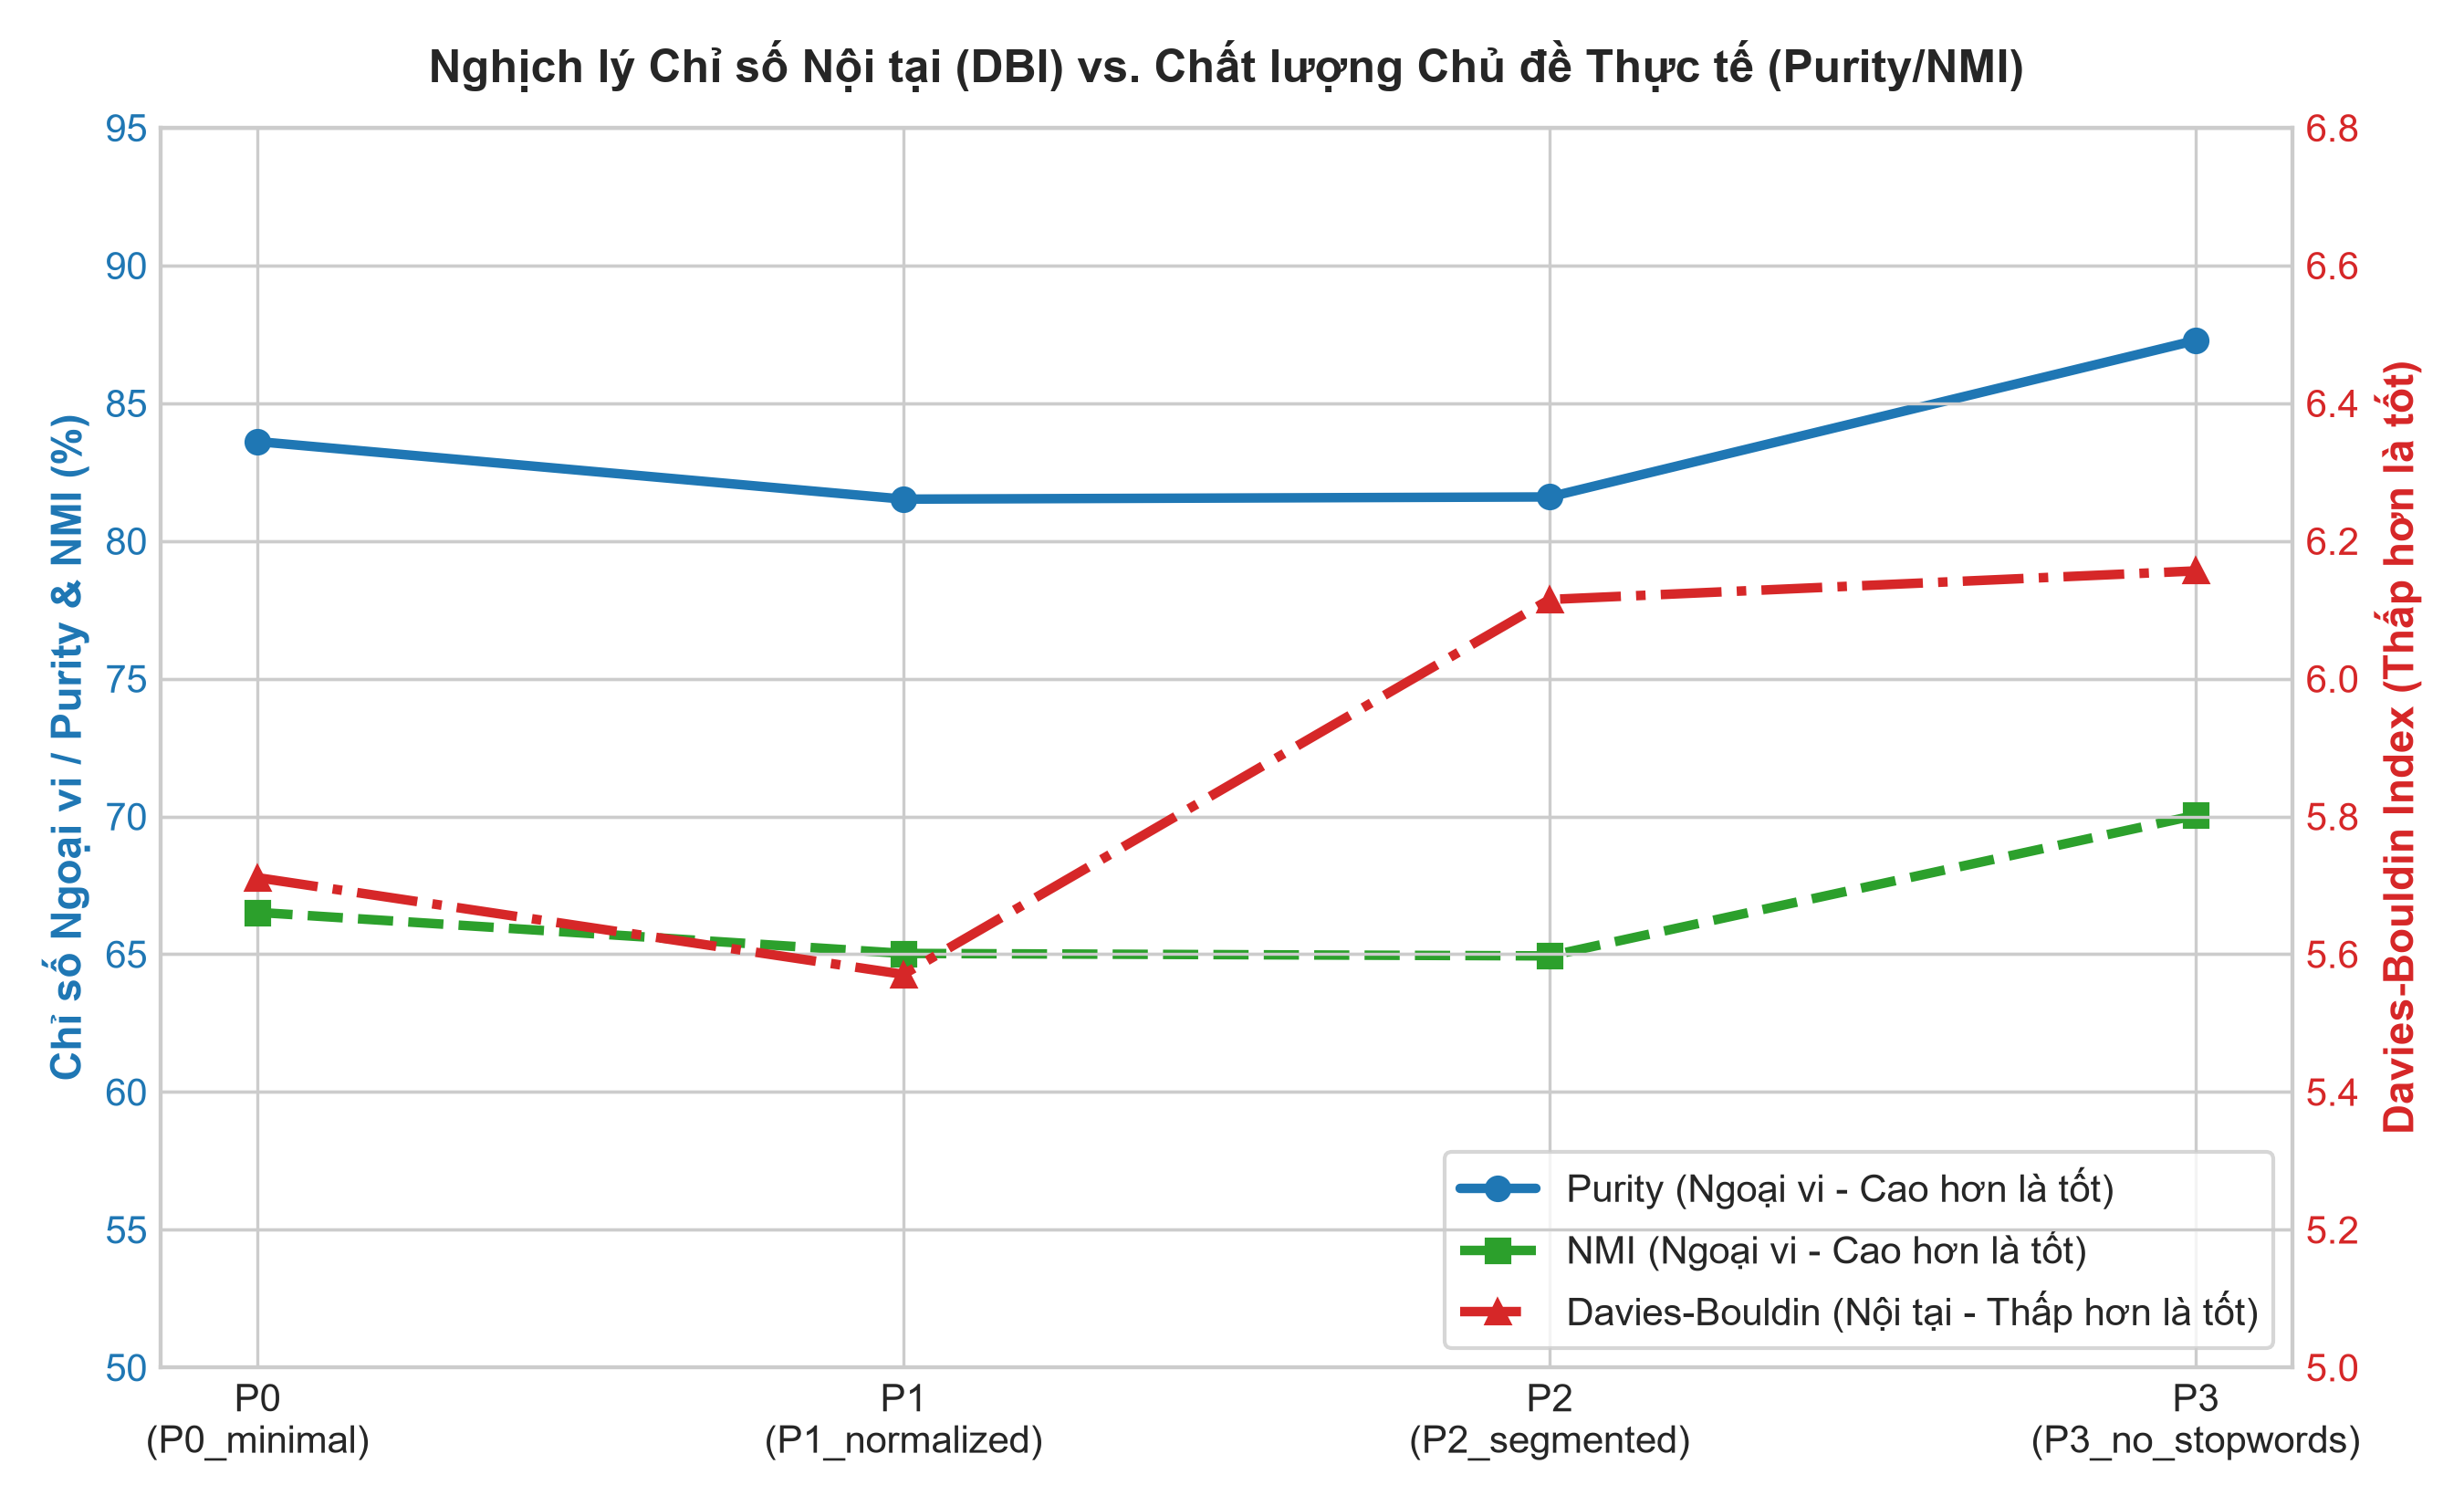

In [4]:
display(Image(filename=str(FIGURES_DIR / "m03_intrinsic_vs_extrinsic_paradox.png")))

### 3.3. Chất lượng Diễn giải Từ vựng (Lexical Interpretability)
- **P0/P1:** 0.0% từ ghép trong top 15, các cụm chứa nhiều âm tiết bị băm nhỏ (`phiếu`, `lãi`, `bác`, `sĩ`).
- **P2:** Tách từ giúp từ ghép tăng vọt lên 32.59% (`bác_sĩ`, `điều_trị`), nhưng vẫn bị ô nhiễm bởi 18.52% từ dừng.
- **P3:** Lọc từ dừng triệt tiêu hoàn toàn ô nhiễm (0.00% từ dừng), đẩy tỷ lệ từ ghép lên **43.70%** và đa dạng từ khóa lên **0.9556**.

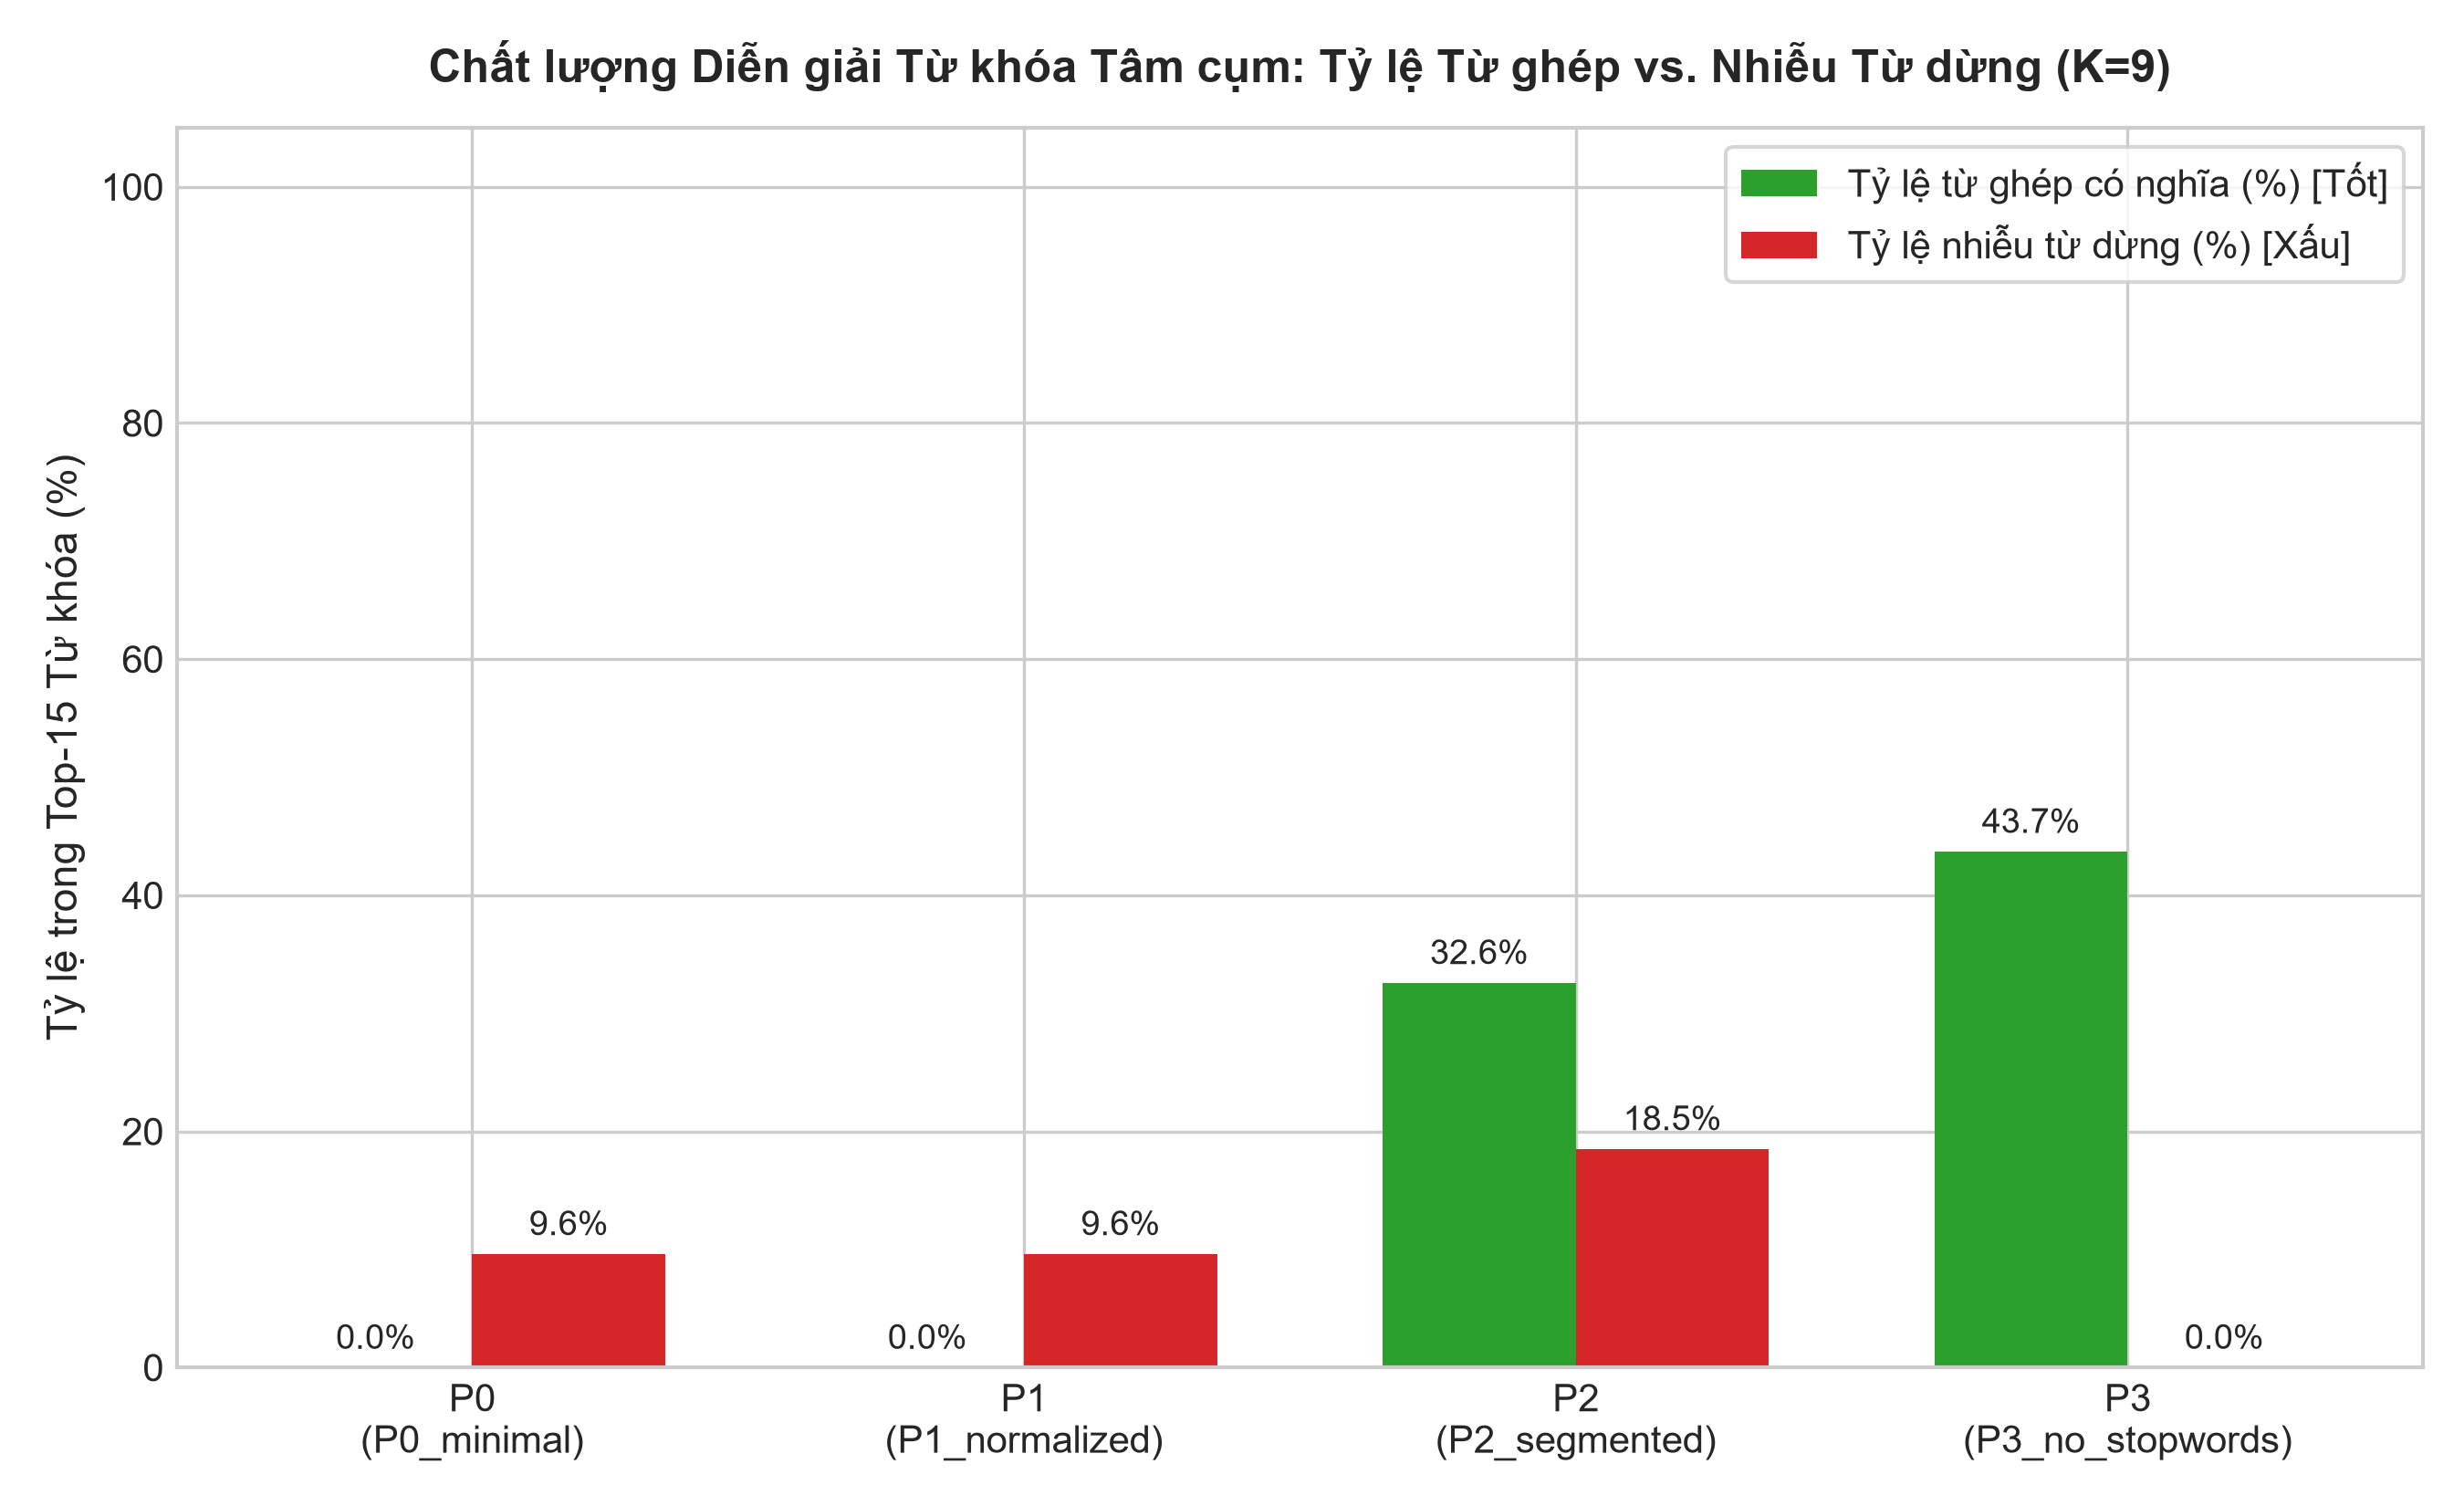

In [5]:
display(Image(filename=str(FIGURES_DIR / "m03_lexical_interpretability.png")))

## 4. Kiểm tra Độ nhạy với Mốc đối chiếu $K=7$ (Sensitivity Analysis)
Đối chiếu với $K=7$ tương ứng 7 nhãn chuyên mục `category_gold` gốc của bộ dữ liệu.

purity             nmi             ari          \
k                7       9       7       9       7       9   
variant_id                                                   
P0          0.7843  0.8361  0.6420  0.6652  0.5505  0.5457   
P1          0.8109  0.8152  0.6683  0.6503  0.6066  0.5161   
P2          0.8152  0.8160  0.6788  0.6494  0.5869  0.4958   
P3          0.8210  0.8728  0.6889  0.7004  0.6239  0.5925   

           stopword_keyword_ratio_pct         
k                                   7      9  
variant_id                                    
P0                              13.33   9.63  
P1                              12.38   9.63  
P2                              21.90  18.52  
P3                               0.00   0.00

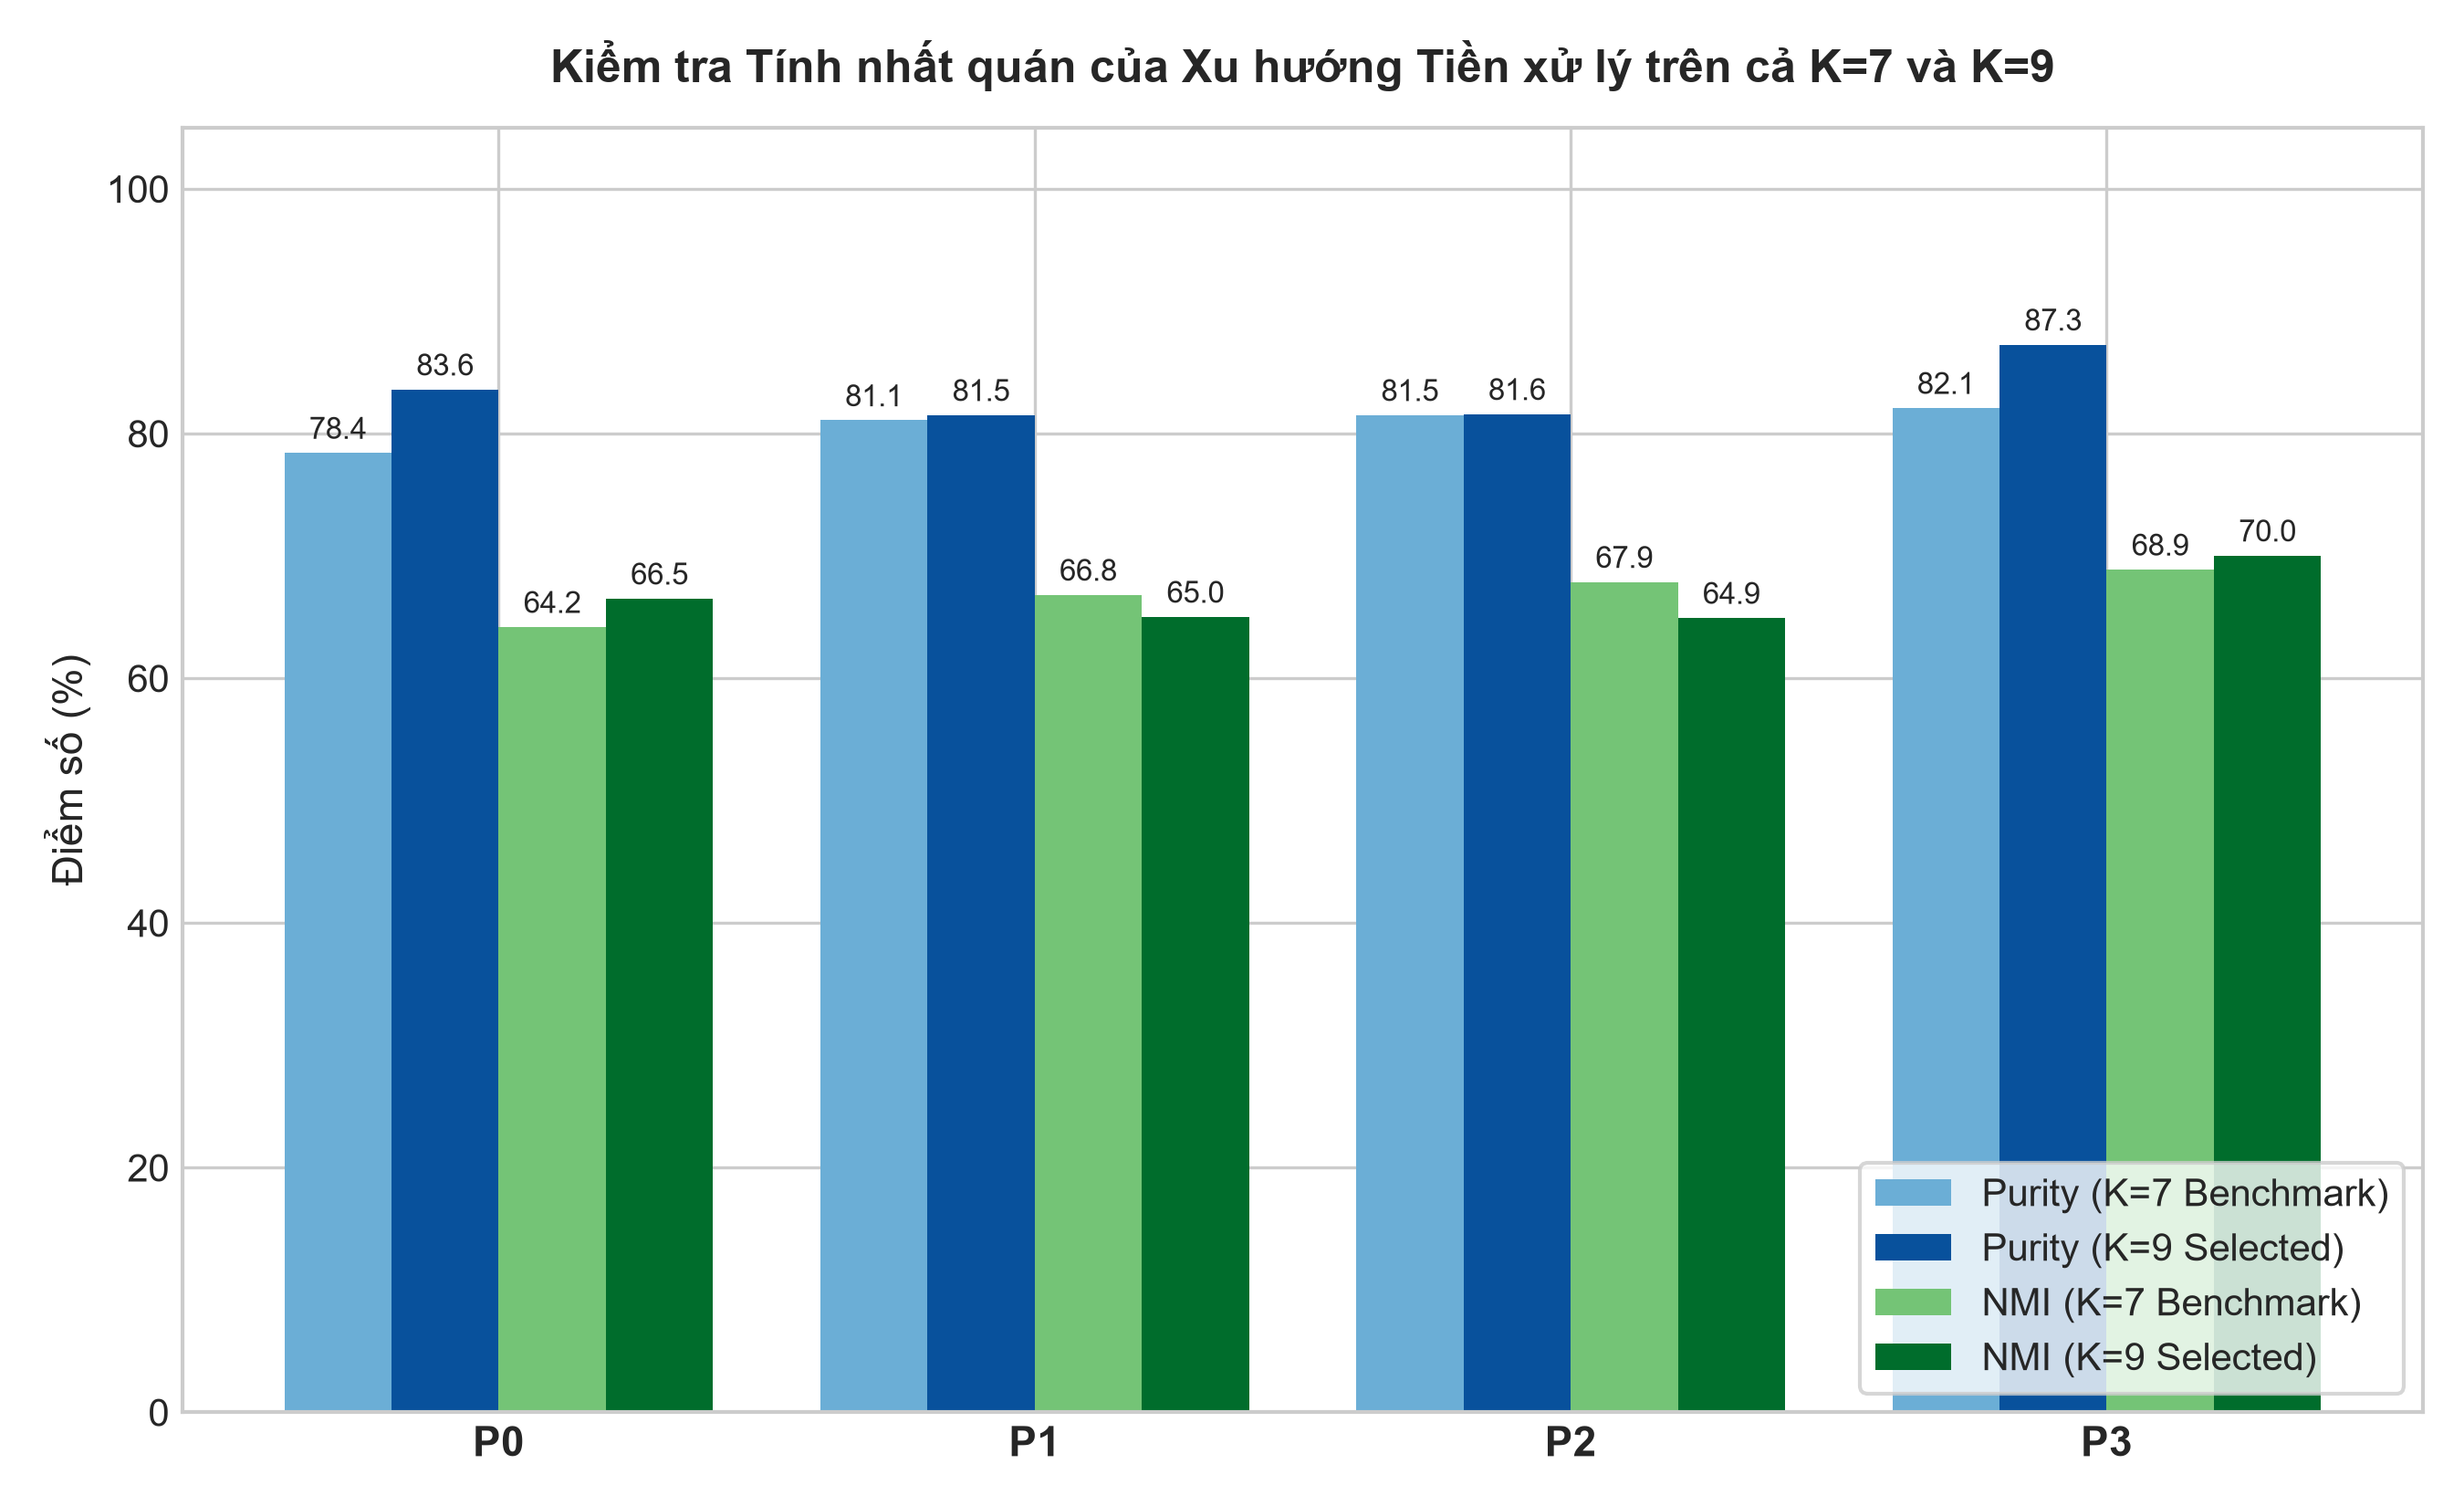

In [6]:
sens_path = RESULTS_DIR / "m03_preprocessing_ablation_k7_sensitivity.csv"
sens_df = pd.read_csv(sens_path)

# Bảng đối chiếu K=7 vs K=9
sens_pivot = sens_df.pivot(index="variant_id", columns="k", values=["purity", "nmi", "ari", "stopword_keyword_ratio_pct"])
display(sens_pivot)

display(Image(filename=str(FIGURES_DIR / "m03_k7_vs_k9_sensitivity.png")))

## 5. Dẫn chứng Định tính Từng Cụm: So sánh P0 vs P3 ($K=9$)
Bảng so sánh trực quan cụ thể các cụm chủ đề giữa dữ liệu chưa qua xử lý (P0) và dữ liệu được tiền xử lý hoàn thiện (P3).

In [7]:
qual_path = RESULTS_DIR / "m03_qualitative_cluster_examples.csv"
qual_df = pd.read_csv(qual_path)

# Lọc các cụm tiêu biểu để so sánh trực quan giữa P0 và P3
p0_sample = qual_df[qual_df["variant_id"] == "P0"][["cluster_id", "dominant_gold_category", "top10_keywords", "nearest_article_title"]]
p3_sample = qual_df[qual_df["variant_id"] == "P3"][["cluster_id", "dominant_gold_category", "top10_keywords", "nearest_article_title"]]

print("=== P0: TIỀN XỬ LÝ TỐI GIẢN (Từ khóa vỡ vụn, dính từ dừng, lẫn chữ hoa) ===")
display(p0_sample.head(5))

print("\n=== P3: TIỀN XỬ LÝ HOÀN THIỆN (Từ ghép chuyên ngành, sạch từ dừng) ===")
display(p3_sample.head(5))

=== P0: TIỀN XỬ LÝ TỐI GIẢN (Từ khóa vỡ vụn, dính từ dừng, lẫn chữ hoa) ===


,cluster_id,dominant_gold_category,top10_keywords,nearest_article_title
0,0,Kinh doanh,"tăng, phiếu, lãi, USD, giảm, mức, giá, so, thị...",Lãi suất vay lên 16%: Doanh nghiệp ôm tiền mặt...
1,1,Khoa học công nghệ,"iPhone, Apple, Pro, Max, gập, 18, Duo, màn, ca...",3 iPhone cao cấp ra mắt tuần này: iPhone 18 Pr...
2,2,Giải trí,"diễn, những, phim, người, cô, năm, ảnh, sự, vi...",Mỹ Anh: Không đợi thành công trong nước rồi mớ...
3,3,Giáo dục,"học, giáo, sinh, dục, trường, Trường, viên, Gi...",5 kỳ vọng lớn của ngành giáo dục năm học mới
4,4,Kinh doanh,"doanh, triển, nghiệp, công, sản, động, phát, t...",Từ thương mại đến hút dòng vốn chất lượng cao:...



=== P3: TIỀN XỬ LÝ HOÀN THIỆN (Từ ghép chuyên ngành, sạch từ dừng) ===


,cluster_id,dominant_gold_category,top10_keywords,nearest_article_title
27,0,Giải trí,"cô, phim, anh, khán_giả, không, diễn_viên, tôi...",Mỹ Anh: Không đợi thành công trong nước rồi mớ...
28,1,Thể thao,"asiad, nữ, u23, nam, giành, thi_đấu, việt_nam,...",Xác định 8 đội vào tứ kết bóng đá nữ Asiad 20
29,2,Khoa học công nghệ,"iphone, apple, pro, máy, dùng, màn_hình, max, ...","Toàn cảnh thông tin hot nhất về iPhone 18 Pro,..."
30,3,Sức khỏe,"bác_sĩ, bệnh, điều_trị, bệnh_viện, người_bệnh,...",5 điều cần biết để giữ thận khỏe
31,4,Thể thao,"trận, đội, bóng, cầu_thủ, hlv, cup, thắng, sân...",HLV tuyển Philippines: 'Chúng tôi không đáng t...


## 6. Kết luận & Đóng góp Nghiên cứu

1. **Trả lời RQ2:** Tiền xử lý có tác động mang tính quyết định đối với phân cụm văn bản tiếng Việt. Chuỗi biến đổi $P0 → P1 → P2 → P3$ giúp tăng Purity từ 83.61% lên **87.28%**, tăng ARI từ 0.5457 lên **0.5925**, và tăng NMI lên **0.7004**.
2. **Giải mã Nghịch lý Hình học:** Các chỉ số hình học thuần túy (DBI, CH) có thể bị đánh lừa bởi các âm tiết đơn lẻ tần số cao kéo co cụm giả tạo. Đánh giá phân cụm tiếng Việt bắt buộc phải kết hợp cả chỉ số ngoại vi (Purity, NMI) và chất lượng diễn giải từ vựng (Compound ratio, Stopword pollution).
3. **Tác động của Tách từ (P2):** Chuyển dịch từ vựng từ cấp độ âm tiết què cụt sang cấp độ từ vựng/khái niệm ngữ nghĩa hoàn chỉnh (tăng từ ghép từ 0% lên 32.6% - 43.7%).
4. **Tác động của Lọc từ dừng (P3):** Quét sạch 100% ô nhiễm từ dừng ở tâm cụm, loại bỏ hiện tượng cụm rác giải trí/kinh doanh bị pha tạp hư từ, giúp ranh giới các chủ đề rõ nét và có tính khái quát cao nhất.